In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import statistics
pd.options.display.max_rows = 400000

In [ ]:
dplt = pd.DataFrame(columns=["nSta","Avg Delay"])
colors = np.random.rand(1006)
area = (30 * np.random.rand(1006))**2
for mcs in range(11, 12):
    for nSta in range(8, 9):
        for node in range(1, 9): 
            dt = pd.read_csv("results/1-downlink-withOfdma-{nSta}-mcs{mcs}/00:00:00:00:00:0{node}".format(nSta=nSta, mcs=mcs,node=node), delimiter="\t")
            #dplt.loc[nSta] = [nSta, dt["Avg_delay_ms"].mean()]
            plt.figure()
            plt.scatter(dt["Delay_ms"], dt["Time_s"])# s=area, c=colors, alpha=0.5)
                        #linestyle='dashed', linewidth = 2, marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
            plt.ylabel("Time in S")
            plt.xlabel("Delay_ms")
            plt.grid(True)
            #plt.legend()
            plt.title("Node {node}".format(node=node))
            plt.savefig("Time_vrs_delay_scatter_mcs{node}.png".format(node=node), dpi=500)

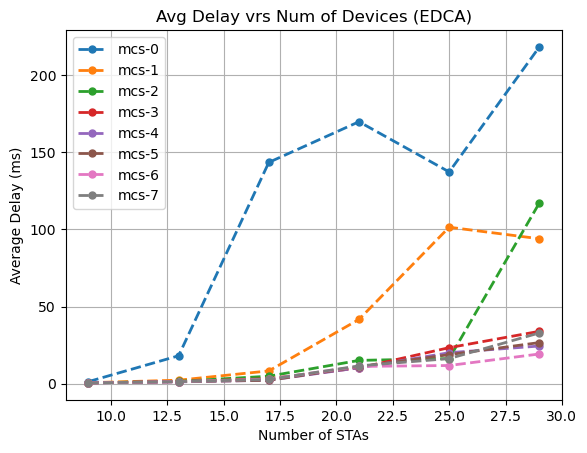

In [14]:

for mcs in range(0, 8):
    dplt = pd.DataFrame(columns=["nSta","Avg Delay", "Std"])
    for nSta in range(9, 31, 4):
        dt = pd.read_csv("results_limits/1-withOfdma-{nSta}-mcs{mcs}/per_sta_stats.out".format(nSta=nSta, mcs=mcs), delimiter="\t")
        dplt.loc[nSta] = [nSta, dt["Avg_delay_ms"].mean(), dt["Avg_delay_ms"].std()]
        #print(dplt)
    plt.plot(dplt["nSta"], dplt["Avg Delay"], linestyle='dashed', linewidth = 2,
         marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Average Delay (ms)")
    #plt.errorbar(dplt["nSta"], dplt["Avg Delay"],yerr=dplt["Std"], fmt='o', capsize=5,
     #            label="mcs-{mcs}".format(mcs=mcs))
    plt.legend()
    plt.grid(True)
    plt.title("Avg Delay vrs Num of Devices (EDCA)")
    #plt.savefig("delay_vrs_Ndev_mcs8-11.png", dpi=500)

/usr/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1335: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return np.asarray(x, float)
/usr/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1335: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return np.asarray(x, float)
/usr/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1335: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return np.asarray(x, float)
/usr/lib/python3.10/site-packages/matplotlib/cbook/__init__.py:1335: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  return np.asarray(x, float)


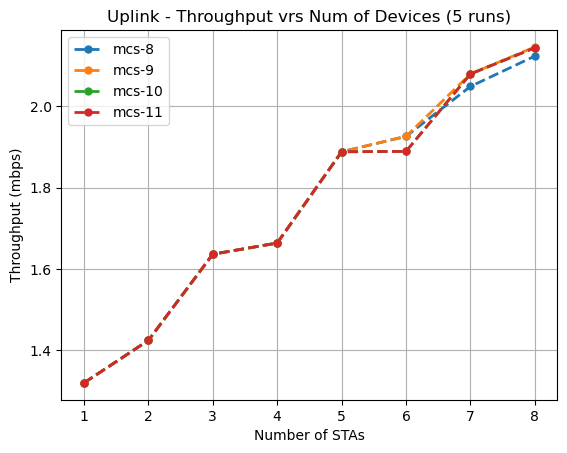

In [26]:

dt = None
for mcs in range(8, 12):
    dplt = pd.DataFrame()
    dtl = {
    "nSta":[],
    "throughput" :[]
    }
    
    for nSta in range(1, 9):
        dt = pd.read_csv("results/1-withOfdma-{nSta}-mcs{mcs}/throughput.out".format(nSta=nSta, mcs=mcs), delimiter="\t")
        #print(dt)
        dtl["nSta"].append(nSta)
        dtl["throughput"].append (dt["Throughput_Mbps"])
    dplt = pd.DataFrame(dtl)

    #plt.figure()
    plt.plot(dplt["nSta"], dplt["throughput"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Throughput (mbps)")
    plt.legend()
    plt.grid(True)
    plt.title("Uplink - Throughput vrs Num of Devices (5 runs)")
    plt.savefig("throughput_vrs_Ndev_mcs8-11.png", dpi=500)

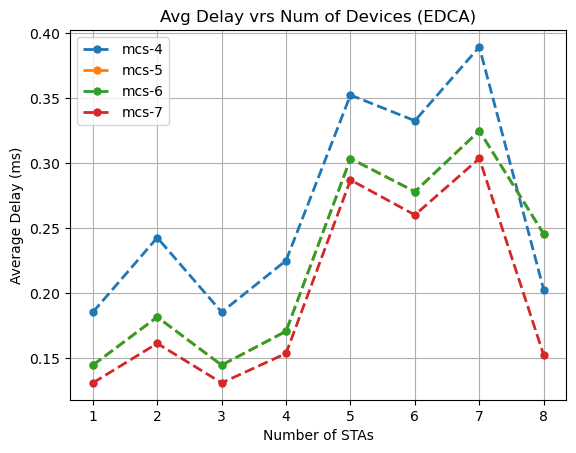

In [27]:
dplt = pd.DataFrame()
dtl = {}
dt = None
for mcs in range(4, 8):
    for runs in range(1, 6):
        dtl["nSta"] = []
        dtl["Avg Delay_{runs}".format(runs=runs)] = []
        for nSta in range(1, 9):
            dt = pd.read_csv("Uplink_Edca/{runs}-withOFDMA-{nSta}-mcs{mcs}/per_sta_stats.out".format(nSta=nSta, mcs=mcs, runs=runs), delimiter="\t")
            #print(type(dt))
            dtl["nSta"].append(nSta)
            #dat = dt[dt["Avg_delay_ms"] < 50]
            dtl["Avg Delay_{runs}".format(runs=runs)].append (dt["Avg_delay_ms"]. mean())
    dplt = pd.DataFrame(dtl)
    dplt["Avg Delay"] = dplt.iloc[:, 1:].mean(axis=1)
    plt.plot(dplt["nSta"], dplt["Avg Delay"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Average Delay (ms)")
    plt.legend()
    plt.grid(True)
    plt.title("Avg Delay vrs Num of Devices (EDCA)")
    plt.savefig("delay_vrs_Ndev_mcs8-11.png", dpi=500)

In [39]:
dplt

,nSta,Avg Delay_1,Avg Delay_2,Avg Delay_3,Avg Delay_4,Avg Delay_5,Avg Delay
0,1,0.152184,0.153684,0.153796,0.153318,0.153942,0.153385
1,2,0.166675,0.166218,0.225746,0.166045,0.230348,0.191006
2,3,0.174820,0.178699,0.175323,0.173795,0.217349,0.183997
3,4,0.180272,0.232552,0.177959,0.177840,0.192447,0.192214
4,5,0.234029,0.181166,0.183362,0.204760,0.503857,0.261435
5,6,0.199544,0.190629,0.203501,0.195289,0.207159,0.199224
6,7,0.206027,0.262760,0.215466,0.227088,0.260702,0.234408
7,8,0.219574,0.203568,0.215597,0.231641,0.218013,0.217679


**Error Bar**

In [ ]:
dplt = pd.DataFrame()

dtl = {}
dt = None
for mcs in range(0, 12):
    for runs in range(1, 6):
        dtl["nSta"] = []
        dtl["Avg Delay_{runs}".format(runs=runs)] = []
        dtl["Std_{runs}".format(runs=runs)] = []
        dtl["Var_{runs}".format(runs=runs)] = []
        for nSta in range(1, 9):
            dt = pd.read_csv("results/{runs}-withEdca-{nSta}-mcs{mcs}/per_sta_stats.out".format(nSta=nSta, mcs=mcs, runs=runs), delimiter="\t")
            #print(type(dt))
            dtl["nSta"].append(nSta)
            #dat = dt[dt["Avg_delay_ms"] < 50]
            dtl["Avg Delay_{runs}".format(runs=runs)].append (dt["Avg_delay_ms"]. mean())
            dtl["Std_{runs}".format(runs=runs)].append (dt["Avg_delay_ms"].std() )
            dtl["Var_{runs}".format(runs=runs)].append (dt["Avg_delay_ms"].var() )
    dplt = pd.DataFrame(dtl)
    dplt["Avg Delay"] = dplt[['Avg Delay_1','Avg Delay_2','Avg Delay_3','Avg Delay_4','Avg Delay_5']].mean(axis=1)
    dplt["sum_var_std"] = np.sqrt(dplt[['Var_1','Var_2','Var_3','Var_4','Var_5']].sum(axis=1)) / 5
    plt.figure()
    #plt.plot(dplt["nSta"], dplt["Avg Delay"], linestyle='dashed', linewidth = 2,
     #   marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Average Delay (ms)")
    plt.errorbar(dplt["nSta"], dplt["Avg Delay"],yerr=dplt["sum_var_std"], fmt='o', capsize=5,
                 label="mcs-{mcs}".format(mcs=mcs))
    plt.legend()
    plt.grid(True)
    plt.title("Error bar (EDCA)")
    plt.savefig("ErrorBar_mcs{mcs}.png".format(mcs=mcs), dpi=500)    
    


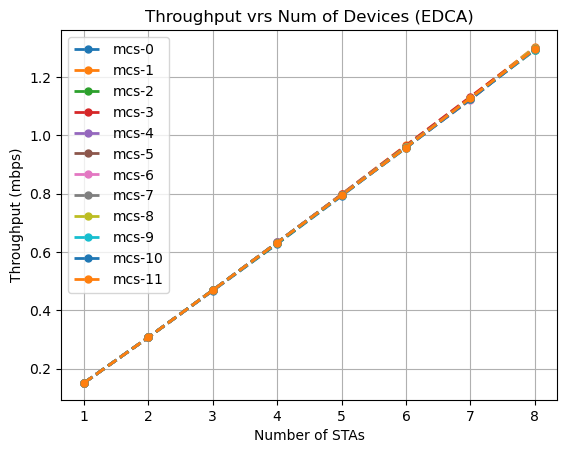

In [9]:
dplt = pd.DataFrame()
dtl = {}
dt = None
for mcs in range(0, 12):
    for runs in range(1, 6):
        dtl["nSta"] = []
        dtl["Avg throughput_{runs}".format(runs=runs)] = []
        for nSta in range(1, 9):
            dt = pd.read_csv("results/{runs}-withEdca-{nSta}-mcs{mcs}/throughput.out".format(nSta=nSta, mcs=mcs, runs=runs), delimiter="\t")
            #print(dt)
            dtl["nSta"].append(nSta)
            dtl["Avg throughput_{runs}".format(runs=runs)].append (dt["Throughput_Mbps"].mean())
    dplt = pd.DataFrame(dtl)
    dplt["Avg Throughput"] = dplt.iloc[:, 1:].mean(axis=1)
    #plt.figure()
    plt.plot(dplt["nSta"], dplt["Avg Throughput"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Throughput (mbps)")
    plt.legend()
    plt.grid(True)
    plt.title("Throughput vrs Num of Devices (EDCA)")
    #plt.savefig("throughput_vrs_Ndev_mcs8-11.png", dpi=500)

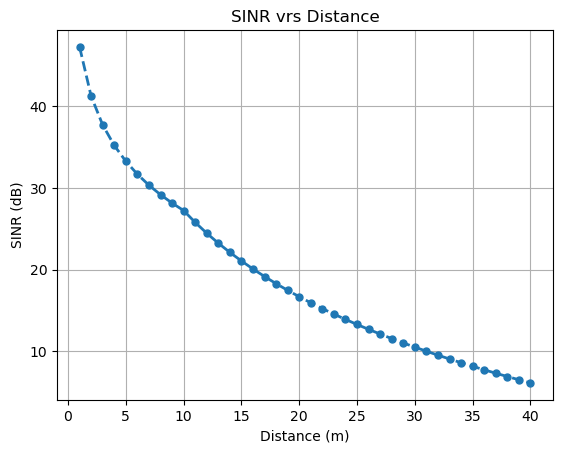

In [10]:
dic = {
    "distance":[],
    "sinr":[]
}
m_frequency = 5150000000
m_exponent1 = 2
m_exponent2 = 3.5
m_breakpointDistance = 10
noise = 10.0 * math.log10(4.01237e-13) + 30.0 


for distance in range(1,41):
    if distance > m_breakpointDistance:
        added_value = 10 * m_exponent2 * math.log10 (distance / m_breakpointDistance)
    else:
        added_value = 0
    pathLossDb = (10 * m_exponent1 * math.log10 (m_frequency) + 10 * m_exponent1 * math.log10 (min (distance, m_breakpointDistance)) - 147.5 ) + added_value;
    #pathLossDb = (0 - pathLossDb) + 30
    #to_W = math.pow(10.0, 0.1 * (-pathLossDb - 30.0))
    #ratio_W = to_W / noise
                    
    dic["distance"].append(distance)
    dic["sinr"].append( -pathLossDb - noise)
    #print(f"{-pathLossDb}\t{added_value}")
df_plt= pd.DataFrame(dic)
#plt.figure()
plt.plot(df_plt["distance"],df_plt["sinr"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5)
plt.xlabel("Distance (m)")
plt.ylabel("SINR (dB)")
#plt.legend()
plt.grid(True)
plt.title("SINR vrs Distance")
plt.savefig("sinr_vs_distance", dpi=500)

## Array file for cluster

In [31]:
run = range (1, 6)
mcs = range (8, 9)
nStations = range (8,9)
interval = range(1, 6)


index = pd.MultiIndex.from_product([run, mcs, nStations, interval], names = ["run","mcs","nStations", "interval"])

pd.DataFrame(index = index).reset_index().to_csv("edca_interval.csv", index=False)

## Televic Scenario

### Mean Averages

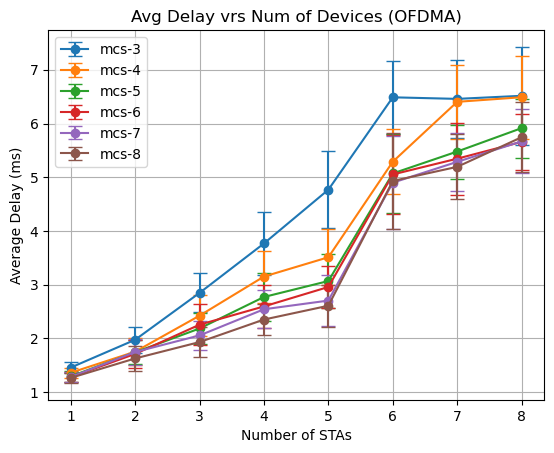

In [105]:
for mcs in range(3, 9):
    dplt = pd.DataFrame()
    for runs in range(1, 6):
        
        for nSta in range(1, 9):
            #read the file (AP)
            df_ap = pd.read_csv("OFDMA_only_DL_B/{runs}run-{nSta}nStations-mcs{mcs}/00:00:00:00:00:{ap_node}".format(runs=runs, nSta=nSta, mcs=mcs, ap_node=hex(nSta+1)[2:].zfill(2) ), delimiter="\t")

            #drop irrelevant colums
            df_ap.drop(columns=["Reception_time", "Delay_ms"], inplace=True, axis=1)

            #dataframe per nSta
            df_nSta = pd.DataFrame()
            
            for node in range(1, nSta + 1):
                
                #read the file (STAs)
                df_sta = pd.read_csv("OFDMA_only_DL_B/{runs}run-{nSta}nStations-mcs{mcs}/00:00:00:00:00:{sta_node}".format(runs=runs, nSta=nSta, mcs=mcs,sta_node=hex(node)[2:].zfill(2) ), delimiter="\t")
                
                #drop *irrelevant colums
                df_sta.drop(columns=["Received_from", "Generation_time", "Delay_ms"], inplace=True, axis=1)

                #Refill/recreate Received_from, populate with the mac of sta. Needed for inner join
                df_sta["Received_from"] = pd.Series(["00:00:00:00:00:{sta_node}".format(sta_node=hex(node)[2:].zfill(2) )  for  x in  range(len(df_sta.index ))])
                
                #Inner join on 'Received_from', 'Packet_Tag'
                df_merged = pd.merge(df_sta, df_ap, how='inner', on=['Received_from', 'Packet_Tag'])       

                #Create a roundtrip delay column
                df_merged["round_trip_time"] = pd.Series( df_merged['Reception_time'] - df_merged['Generation_time'] )
                
                #append the two dataframes
                df_nSta = pd.concat([df_nSta, df_merged], ignore_index=True)
                
                
            df_nSta["nSta"] = pd.Series([nSta  for x in range(len(df_nSta.index ))])

            dplt = pd.concat([dplt, df_nSta], ignore_index=True)
            
   
    dplt.drop(columns=["Reception_time", "Received_from", "Generation_time", "Packet_Tag"], inplace=True, axis=1)
    
    df_mean = dplt.groupby('nSta', as_index=False).mean()
    df_std = dplt.groupby('nSta', as_index=False).std()

    plt.errorbar(df_mean["nSta"], df_mean["round_trip_time"],yerr=df_std["round_trip_time"], fmt='-o',capsize=5,
                 label="mcs-{mcs}".format(mcs=mcs))
    
    plt.xlabel("Number of STAs")
    plt.ylabel("Average Delay (ms)")
    plt.legend()
    plt.grid(True)
    plt.title("Avg Delay vrs Num of Devices (OFDMA)")
    #plt.savefig("OFDMA_only_Avg_mcs_3_8.png", dpi=500)

### Percentile

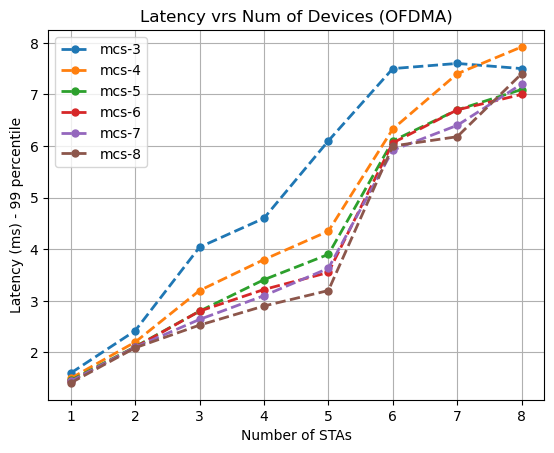

In [108]:
for mcs in range(3, 9):
    dplt = pd.DataFrame()
    for runs in range(1, 6):
        for nSta in range(1, 9):
            #read the file (AP)
            df_ap = pd.read_csv("OFDMA_only_DL_B/{runs}run-{nSta}nStations-mcs{mcs}/00:00:00:00:00:{ap_node}".format(runs=runs, nSta=nSta, mcs=mcs, ap_node=hex(nSta+1)[2:].zfill(2) ), delimiter="\t")

            #drop irrelevant colums
            df_ap.drop(columns=["Reception_time", "Delay_ms"], inplace=True, axis=1)
            ##check if the file is empty
            if df_ap.dropna(how='all').empty:
                print(f"no data in {nSta} nStations {runs} runs {mcs} mcs")

            #dataframe per nSta
            df_nSta = pd.DataFrame()
                        
            for node in range(1, nSta + 1):
                #read the file (STAs)
                df_sta = pd.read_csv("OFDMA_only_DL_B/{runs}run-{nSta}nStations-mcs{mcs}/00:00:00:00:00:{sta_node}".format(runs=runs, nSta=nSta, mcs=mcs, sta_node=hex(node)[2:].zfill(2) ), delimiter="\t")
                
                #drop *irrelevant colums
                df_sta.drop(columns=["Received_from", "Generation_time", "Delay_ms"], inplace=True, axis=1)

                #group by packet_tag and find the mean delay of packets sent by the AP
                #df_sta_gb = df_sta.groupby('Packet_Tag', as_index=False).quantile(q=.99)
                
                #check if the file is empty
                if df_sta.dropna(how='all').empty:
                    print(f"no data in {nSta} nStations {runs} runs {mcs} mcs")

                #Refill/recreate Received_from, populate with the mac of sta. Needed for inner join
                df_sta["Received_from"] = pd.Series(["00:00:00:00:00:{sta_node}".format(sta_node=hex(node)[2:].zfill(2) )  for x in range(len(df_sta.index ))])

                #Inner join on 'Received_from', 'Packet_Tag'
                df_merged = pd.merge(df_sta, df_ap, how='inner', on=['Received_from', 'Packet_Tag'])

                #Create a roundtrip delay column
                df_merged["round_trip_time"] = pd.Series( df_merged['Reception_time'] - df_merged['Generation_time'])
                
                #append the two dataframes
                df_nSta = pd.concat([df_nSta, df_merged], ignore_index=True)
            

            df_nSta["nSta"] = pd.Series([nSta  for x in range(len(df_nSta.index ))])

            dplt = pd.concat([dplt, df_nSta], ignore_index=True)
            

    #dplt = pd.DataFrame(dict_for_data)
    dplt.drop(columns=["Reception_time", "Received_from", "Generation_time", "Packet_Tag"], inplace=True, axis=1)

    to_plot = dplt.groupby('nSta', as_index=False).quantile(q=.99)

    plt.plot(to_plot["nSta"], to_plot["round_trip_time"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Latency (ms) - 99 percentile")
    plt.legend()
    plt.grid(True)
    plt.title("Latency vrs Num of Devices (OFDMA)")
    #plt.savefig("OFDMA_only_Percentile_mcs_3_8.png", dpi=500)

### DL Only
#### Average mean

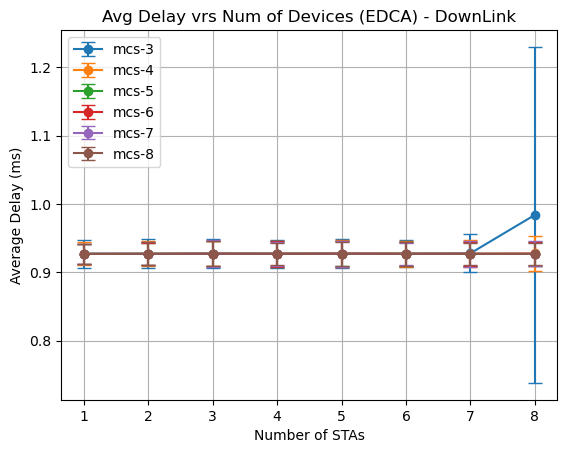

In [15]:
for mcs in range(3, 9):
    dplt = pd.DataFrame()
    for runs in range(1, 6):
        
        for nSta in range(1, 9):
            
            #dataframe per nSta
            df_nSta = pd.DataFrame()
            #print(f"sta: {nSta}\n")
            
            for node in range(1, nSta + 1):
                #read the file (STAs)
                df_sta = pd.read_csv("EDCA_only_DL_B/{runs}run-{nSta}nStations-mcs{mcs}/00:00:00:00:00:0{sta_node}".format(runs=runs, nSta=nSta, mcs=mcs,sta_node=node), delimiter="\t")
                
                #drop *irrelevant colums
                df_sta.drop(columns=["Received_from", "Generation_time", "Reception_time"], inplace=True, axis=1)

                #concat to df_nSta
                df_nSta = pd.concat([df_nSta, df_sta], ignore_index=True)
                
                #append the two dataframes
                df_nSta = pd.concat([df_nSta, df_sta], ignore_index=True)

            
            #label as number of station
            df_nSta["nSta"] = pd.Series([nSta  for x in range(len(df_nSta.index ))])

            #concat to 
            dplt = pd.concat([dplt, df_nSta], ignore_index=True)


    #dplt = pd.DataFrame(dict_for_data)
    dplt.drop(columns=[ "Packet_Tag"], inplace=True, axis=1)

    df_mean = dplt.groupby('nSta', as_index=False).mean()
    df_std = dplt.groupby('nSta', as_index=False).std()
    
    plt.errorbar(df_mean["nSta"], df_mean["Delay_ms"],yerr=df_std["Delay_ms"], fmt='-o' ,capsize=5,
                 label="mcs-{mcs}".format(mcs=mcs))
    
    plt.xlabel("Number of STAs")
    plt.ylabel("Average Delay (ms)")
    plt.legend()
    plt.grid(True)
    plt.title("Avg Delay vrs Num of Devices (EDCA) - DownLink")
    #plt.savefig("EDCA_DownLink_Avg_mcs_3_8.png", dpi=500)

#### Percentile

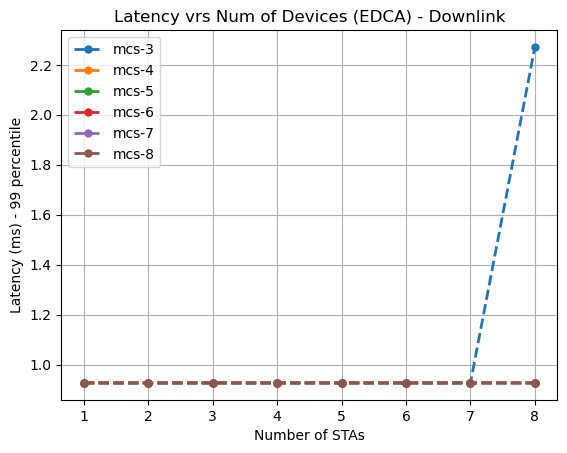

In [16]:
for mcs in range(3, 9):
    dplt = pd.DataFrame()
    
    for runs in range(1, 6):
        
        for nSta in range(1, 9):

            df_nSta = pd.DataFrame()

            for node in range(1, nSta + 1):
                #read the file (STAs)
                df_sta = pd.read_csv("EDCA_only_DL_B/{runs}run-{nSta}nStations-mcs{mcs}/00:00:00:00:00:{sta_node}".format(runs=runs, nSta=nSta, mcs=mcs, sta_node=hex(node)[2:].zfill(2) ), delimiter="\t")
                
                #drop *irrelevant colums
                df_sta.drop(columns=["Received_from", "Generation_time", "Reception_time"], inplace=True, axis=1)

                #concat to df_nSta
                df_nSta = pd.concat([df_nSta, df_sta], ignore_index=True)

            #label as number of station
            df_nSta["nSta"] = pd.Series([nSta  for x in range(len(df_nSta.index ))])

            #concat to 
            dplt = pd.concat([dplt, df_nSta], ignore_index=True)
            

    dplt.drop(columns=["Packet_Tag"], inplace=True, axis=1)

    to_plot = dplt.groupby('nSta', as_index=False).quantile(q=.99)
    
    #print(f"dplt: \n{dplt.head()}")
    #dplt["Avg Delay"] = dplt.iloc[:, 1:].mean(axis=1)
    plt.plot(to_plot["nSta"], to_plot["Delay_ms"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Latency (ms) - 99 percentile")
    plt.legend()
    plt.grid(True)
    plt.title("Latency vrs Num of Devices (EDCA) - Downlink")
    #plt.savefig("EDCA_DownLink_Percentile_mcs_3_8.png", dpi=500)

### UL Only

#### Average Mean

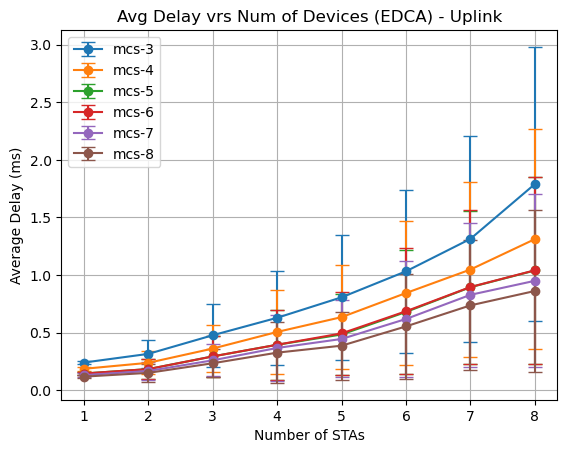

In [19]:
for mcs in range(3, 9):
    dplt = pd.DataFrame()
    for runs in range(1, 6):
        for nSta in range(1, 9):
            #read the file (AP)
            df_ap = pd.read_csv("EDCA_only_DL_B/{runs}run-{nSta}nStations-mcs{mcs}/00:00:00:00:00:0{ap_node}".format(runs=runs, nSta=nSta, mcs=mcs, ap_node=nSta+1), delimiter="\t")            
            #drop irrelevant colums
            df_ap.drop(columns=["Generation_time", "Reception_time", "Received_from"], inplace=True, axis=1)
            #label as number of station
            df_ap["nSta"] = pd.Series([nSta  for x in range(len(df_ap.index ))])
            #concat to 
            dplt = pd.concat([dplt, df_ap], ignore_index=True)

    dplt.drop(columns=["Packet_Tag"], inplace=True, axis=1)

    df_mean = dplt.groupby('nSta', as_index=False).mean()
    df_std = dplt.groupby('nSta', as_index=False).std()
    
    plt.errorbar(df_mean["nSta"], df_mean["Delay_ms"],yerr=df_std["Delay_ms"], fmt='-o' ,capsize=5,
                 label="mcs-{mcs}".format(mcs=mcs))
    
    plt.xlabel("Number of STAs")
    plt.ylabel("Average Delay (ms)")
    plt.legend()
    plt.grid(True)
    plt.title("Avg Delay vrs Num of Devices (EDCA) - Uplink")
    #plt.savefig("EDCA_UpLink_Avg_mcs_3_8.png", dpi=500)

#### Percentile

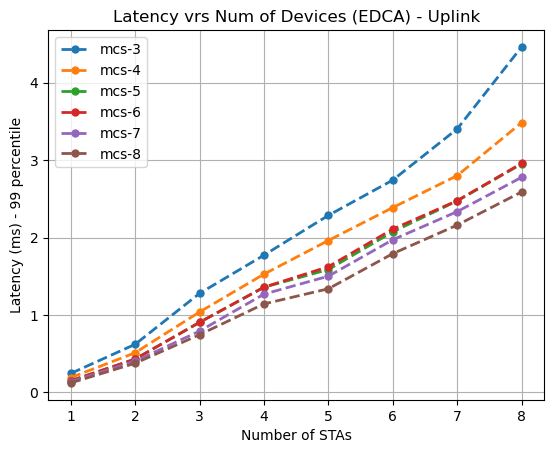

In [20]:
for mcs in range(3, 9):
    dplt = pd.DataFrame()
    for runs in range(1, 6):
        for nSta in range(1, 9):
            #read the file (AP)
            df_ap = pd.read_csv("EDCA_only_DL_B/{runs}run-{nSta}nStations-mcs{mcs}/00:00:00:00:00:0{ap_node}".format(runs=runs, nSta=nSta, mcs=mcs, ap_node=nSta+1), delimiter="\t")            
            #drop irrelevant colums
            df_ap.drop(columns=["Generation_time", "Reception_time", "Received_from"], inplace=True, axis=1)
            #label as number of station
            df_ap["nSta"] = pd.Series([nSta  for x in range(len(df_ap.index ))])
            #concat to 
            dplt = pd.concat([dplt, df_ap], ignore_index=True)

    dplt.drop(columns=[ "Packet_Tag"], inplace=True, axis=1)

    to_plot = dplt.groupby('nSta', as_index=False).quantile(q=.99)
    
    plt.plot(to_plot["nSta"], to_plot["Delay_ms"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Latency (ms) - 99 percentile")
    plt.legend()
    plt.grid(True)
    plt.title("Latency vrs Num of Devices (EDCA) - Uplink")
    #plt.savefig("EDCA_UpLink_Percentile_mcs_3_8.png", dpi=500)

### Packet Loss Rate

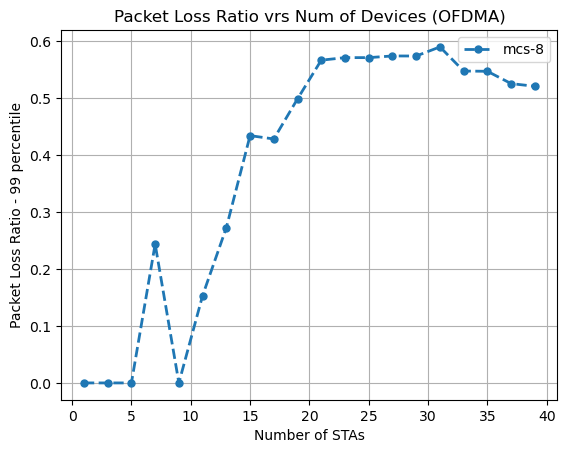

In [41]:
for mcs in range(8, 9):
    dplt = pd.DataFrame()
    for runs in range(1, 6):
        for nSta in range(1, 40, 2):
            #read the file (AP)
            df_ap = pd.read_csv("OFDMA_only_limits_B/{runs}run-{nSta}nStations-mcs{mcs}/per_sta_stats.out".format(runs=runs, nSta=nSta, mcs=mcs), delimiter="\t")            
            #drop irrelevant colums
            df_ap.drop(columns=["MAC-addr", "SINR_dB", "RX_bytes", "Avg_delay_ms"], inplace=True, axis=1)
            #label as number of station
            df_ap["nSta"] = pd.Series([nSta  for x in range(len(df_ap.index ))])
            #concat to 
            dplt = pd.concat([dplt, df_ap], ignore_index=True)

    #dplt.drop(columns=[ "Packet_Tag"], inplace=True, axis=1)

    to_plot = dplt.groupby('nSta', as_index=False).quantile(q=.99)
    
    plt.plot(to_plot["nSta"], to_plot["Packet_loss_ratio"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="mcs-{mcs}".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Packet Loss Ratio - 99 percentile")
    plt.legend()
    plt.grid(True)
    plt.title("Packet Loss Ratio vrs Num of Devices (OFDMA)")
    #plt.savefig("OFDMA_limit_Packet_Loss_Ratio_mcs_3_8.png", dpi=500)

### Interval

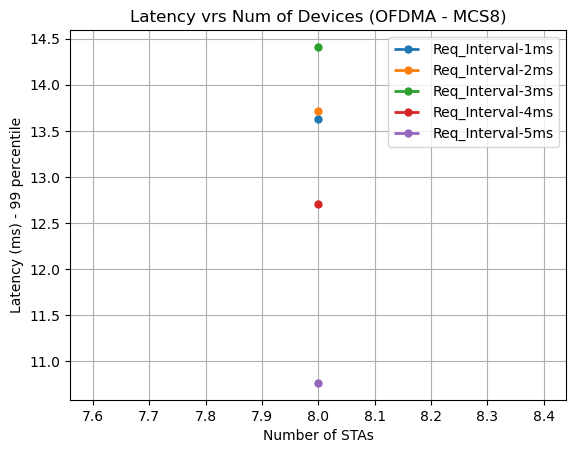

In [33]:
for mcs in range(1, 6):
    dplt = pd.DataFrame()
    for runs in range(1, 6):
        for nSta in range(8, 9):
            #read the file (AP)
            df_ap = pd.read_csv("OFDMA_only_Int/{runs}run-{nSta}nStations-mcs8-interval{mcs}ms/00:00:00:00:00:{ap_node}".format(runs=runs, nSta=nSta, mcs=mcs, ap_node=hex(nSta+1)[2:].zfill(2) ), delimiter="\t")

            #drop irrelevant colums
            df_ap.drop(columns=["Reception_time", "Delay_ms"], inplace=True, axis=1)
            ##check if the file is empty
            if df_ap.dropna(how='all').empty:
                print(f"no data in {nSta} nStations {runs} runs {mcs} mcs")

            #dataframe per nSta
            df_nSta = pd.DataFrame()
                        
            for node in range(1, nSta + 1):
                #read the file (STAs)
                df_sta = pd.read_csv("OFDMA_only_Int/{runs}run-{nSta}nStations-mcs8-interval{mcs}ms/00:00:00:00:00:{sta_node}".format(runs=runs, nSta=nSta, mcs=mcs, sta_node=hex(node)[2:].zfill(2) ), delimiter="\t")
                
                #drop *irrelevant colums
                df_sta.drop(columns=["Received_from", "Generation_time", "Delay_ms"], inplace=True, axis=1)

                #group by packet_tag and find the mean delay of packets sent by the AP
                #df_sta_gb = df_sta.groupby('Packet_Tag', as_index=False).quantile(q=.99)
                
                #check if the file is empty
                if df_sta.dropna(how='all').empty:
                    print(f"no data in {nSta} nStations {runs} runs {mcs} mcs")

                #Refill/recreate Received_from, populate with the mac of sta. Needed for inner join
                df_sta["Received_from"] = pd.Series(["00:00:00:00:00:{sta_node}".format(sta_node=hex(node)[2:].zfill(2) )  for x in range(len(df_sta.index ))])

                #Inner join on 'Received_from', 'Packet_Tag'
                df_merged = pd.merge(df_sta, df_ap, how='inner', on=['Received_from', 'Packet_Tag'])

                #Create a roundtrip delay column
                df_merged["round_trip_time"] = pd.Series( df_merged['Reception_time'] - df_merged['Generation_time'])
                
                #append the two dataframes
                df_nSta = pd.concat([df_nSta, df_merged], ignore_index=True)
            

            df_nSta["nSta"] = pd.Series([nSta  for x in range(len(df_nSta.index ))])

            dplt = pd.concat([dplt, df_nSta], ignore_index=True)
            

    #dplt = pd.DataFrame(dict_for_data)
    dplt.drop(columns=["Reception_time", "Received_from", "Generation_time", "Packet_Tag"], inplace=True, axis=1)

    to_plot = dplt.groupby('nSta', as_index=False).quantile(q=.99)

    plt.plot(to_plot["nSta"], to_plot["round_trip_time"], linestyle='dashed', linewidth = 2,
        marker='o', markersize=5, label="Req_Interval-{mcs}ms".format(mcs=mcs))
    plt.xlabel("Number of STAs")
    plt.ylabel("Latency (ms) - 99 percentile")
    plt.legend()
    plt.grid(True)
    plt.title("Latency vrs Num of Devices (OFDMA - MCS8)")
    plt.savefig("OFDMA_Req_interval_Percentile_mcs_8.png", dpi=500)